# SecondLook | 04 Explainability with SHAP

**Goal:** for any applicant, show **why** the model gave that risk score, in terms a loan officer and the applicant can understand.

**Why this matters for SecondLook:**
- **Fairness and regulation.** When a lender declines someone, many regulators expect the applicant to be told the main reasons. A score with no reasons is a black box.
- **Trust.** A loan officer won't act on a number they can't question.
- **It powers the rest of the app.** The **decision letter** (Step 6) is written from these reasons, the **faithfulness check** compares the letter against them, and the **path to approval** (Phase 2) targets the reasons the applicant can actually change.

### What is SHAP?

SHAP (SHapley Additive exPlanations) comes from **game theory**: it treats the features as "players" sharing out a prediction and works out each one's fair share. For one applicant:

```
model output = base value (the average applicant) + contribution of feature 1 + contribution of feature 2 + ...
```

- A **positive** contribution pushes this applicant's risk **up**; a **negative** one pushes it **down**.
- The contributions **add up exactly** to the model's output, so nothing is hidden or approximated.
- For LightGBM, SHAP works in **log-odds** (the scale the model uses internally). A bigger number means a bigger push; we convert the final result back to a probability (PD) at the end.

| Section | What we do |
|---|---|
| 2 | Load the model and recreate the exact test set from Step 4 |
| 3 | Compute SHAP values and **verify** they add up to the model's output |
| 4 | **Global view:** which features matter most, and in which direction |
| 5 | **Dependence:** how risk changes as a feature changes |
| 6 | **Local view:** explain three individual applicants (approve, borderline, decline) |
| 7 | **Borderline applicants:** what usually pushes them over the cutoff, and can they change it? |

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL, PROCESSED_DIR
from secondlook.features import load_features
from secondlook import modeling as M
from secondlook.explain import Explainer, label_of, category_of, format_value

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")

## 2. Load the model and the test set

We load the saved LightGBM model and its settings (`model_meta.json`), and recreate the **same** stratified test split as Step 4 (same random seed). We then confirm that the predictions match the ones saved in Step 4 exactly, so we're explaining the very same model and applicants.

In [2]:
model, meta = M.load_model()
df = load_features()
train, test = M.split(df)
X_test = M.prepare_X(test, meta["features"], meta["categorical"], meta["categories"])
pd_test = pd.Series(model.predict_proba(X_test)[:, 1], index=test.index)

saved = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")
assert (saved[ID_COL].values == test[ID_COL].values).all() and np.allclose(saved["PD_LGBM"], pd_test)
cutoff = meta["cutoff"]
print(f"Test applicants: {len(test):,}   Features: {X_test.shape[1]}   Cutoff: PD {cutoff}")
print("Predictions identical to Step 4: OK")

Test applicants: 61,503   Features: 158   Cutoff: PD 0.17
Predictions identical to Step 4: OK


## 3. Compute SHAP values and check that they add up

We use SHAP's `TreeExplainer`, which computes **exact** SHAP values for tree models quickly. For the global charts we use a random sample of **5,000 test applicants**, which is plenty to show the patterns and takes seconds.

**Verification:** for every applicant, *base value + sum of SHAP values* must equal the model's raw output. If it doesn't, the explanation can't be trusted.

In [3]:
explainer = Explainer(model)
sample = X_test.sample(5000, random_state=42)
shap_values = explainer.shap_values(sample)
raw_output = model.booster_.predict(sample, raw_score=True)
max_error = np.abs(explainer.base_value + shap_values.sum(axis=1) - raw_output).max()

print(f"SHAP matrix: {shap_values.shape[0]:,} applicants x {shap_values.shape[1]} features")
print(f"Base value: {explainer.base_value:.3f} log-odds  =  PD {explainer.base_value and 1 / (1 + np.exp(-explainer.base_value)):.1%}")
print(f"Largest additivity error: {max_error:.1e}")

SHAP matrix: 5,000 applicants x 158 features
Base value: -2.943 log-odds  =  PD 5.0%
Largest additivity error: 2.3e-14


**Interpretation:**
- **The contributions add up exactly:** the largest error is around 10⁻¹⁴, i.e. rounding noise. Every explanation in this notebook and in the app accounts for **100% of the score**.
- **The base value (≈ −2.94 log-odds, ≈ 5% PD)** is the starting point before looking at any feature. It's lower than the 8% average default rate because SHAP averages on the log-odds scale, where a minority of very risky applicants pulls the *average probability* up more than the *average log-odds*. Each applicant's own features then move the score up or down from there.

## 4. Global view: what drives risk across all applicants?

### 4.1 Mean absolute SHAP: which features matter most?

The average size of each feature's contribution (ignoring direction) shows how much it moves scores **in practice**. Unlike LightGBM's gain importance (Step 4), it's measured on actual applicants' predictions and is consistent with the individual explanations.

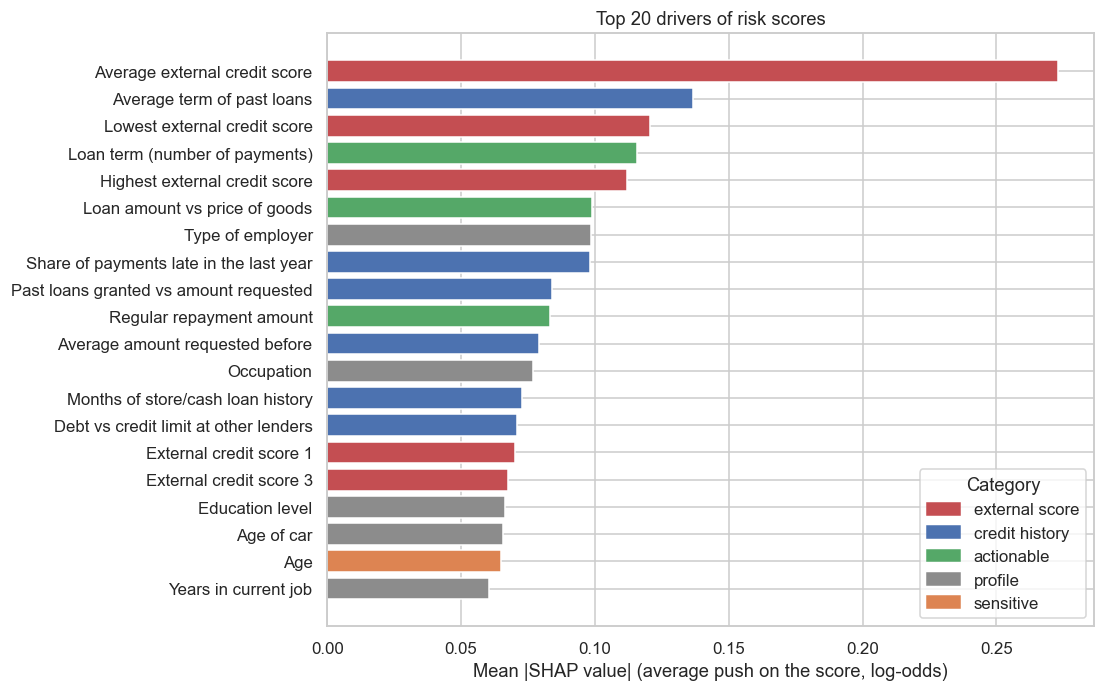

,label,feature,category,mean |SHAP|
0,Average external credit score,EXT_SOURCE_MEAN,external score,0.273
1,Average term of past loans,PREV_AVG_TERM,credit history,0.136
2,Lowest external credit score,EXT_SOURCE_MIN,external score,0.121
3,Loan term (number of payments),CREDIT_TERM,actionable,0.116
4,Highest external credit score,EXT_SOURCE_MAX,external score,0.112
5,Loan amount vs price of goods,CREDIT_TO_GOODS,actionable,0.099
6,Type of employer,ORGANIZATION_TYPE,profile,0.099
7,Share of payments late in the last year,INST_LATE_SHARE_LAST_YEAR,credit history,0.098
8,Past loans granted vs amount requested,PREV_AVG_GRANTED_TO_APPLIED,credit history,0.084
9,Regular repayment amount,AMT_ANNUITY,actionable,0.083


In [4]:
importance = pd.DataFrame({
    "feature": sample.columns,
    "mean |SHAP|": np.abs(shap_values).mean(axis=0),
}).sort_values("mean |SHAP|", ascending=False).reset_index(drop=True)
importance["label"] = importance["feature"].map(label_of)
importance["category"] = importance["feature"].map(category_of)

palette = {"external score": "#C44E52", "credit history": "#4C72B0", "actionable": "#55A868", "profile": "#8C8C8C", "sensitive": "#DD8452"}
top = importance.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["label"], top["mean |SHAP|"], color=top["category"].map(palette))
ax.set_xlabel("Mean |SHAP value| (average push on the score, log-odds)")
ax.set_title("Top 20 drivers of risk scores")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), title="Category", loc="lower right")
save(fig, "19_shap_importance")
plt.show()
importance.head(20)[["label", "feature", "category", "mean |SHAP|"]]

**Interpretation:**
- **The average external score is by far the biggest driver**, about twice as strong as anything else, consistent with EDA, Step 3 and Step 4.
- **Past behaviour (blue)** is the next big group: the **average term of past loans** ranks second overall, followed by late payments in the last year, past loans granted vs requested, the amount requested before and debt vs credit at other lenders.
- **Actionable loan terms (green)** are among the top drivers: **loan term**, **loan amount vs price of goods** and the **regular repayment amount**. Because these can be changed when an application is restructured, they are SecondLook's levers for a path to approval.
- **Employer and occupation** (grey) also matter.
- One **sensitive** feature appears: **age**, at #19 with a small average effect. The model may use age as a background signal, but we never suggest changing it, and the letters won't cite it. Section 7 checks whether it actually drives decisions near the cutoff.

### 4.2 Beeswarm: direction and spread

Each dot is one applicant. Its **horizontal position** is the feature's push on their score (right = riskier), and its **colour** is the feature's value (red = high, blue = low). This shows not just *how much* a feature matters, but *which way*.

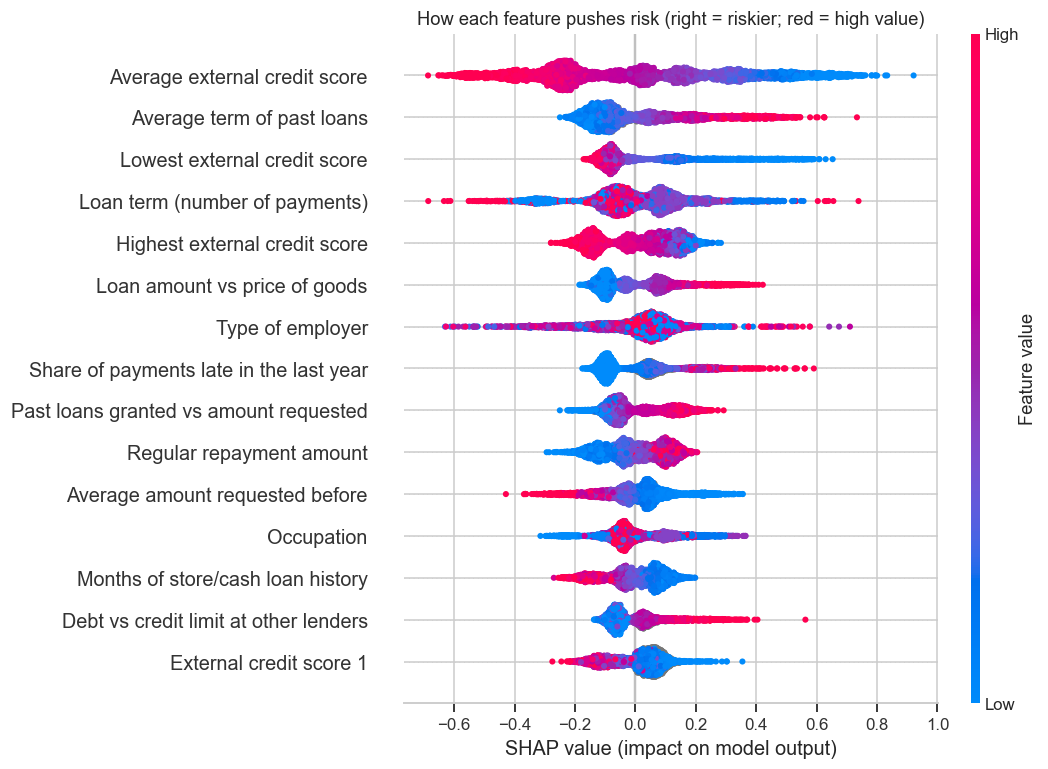

In [5]:
plot_data = sample.copy()
for c in meta["categorical"]:
    plot_data[c] = plot_data[c].cat.codes.replace(-1, np.nan)   # colour needs numbers; categories -> codes
plot_data.columns = [label_of(c) for c in plot_data.columns]

plt.figure()
shap.summary_plot(shap_values, plot_data, max_display=15, show=False, plot_size=(10, 7))
plt.title("How each feature pushes risk (right = riskier; red = high value)")
save(plt.gcf(), "20_shap_beeswarm")
plt.show()

**How to read it:** for the **average external credit score**, red dots (high scores) sit on the **left** (lower risk) and blue dots (low scores) on the **right** (higher risk). Higher score, lower risk, as expected. For **late payments in the last year**, red dots sit on the right: more late payments, more risk. For **average term of past loans**, red (long past loans) sits on the right: applicants who previously needed long loans tend to be riskier.

For categorical features (employer, occupation) the colour is just a category code and has no high/low meaning. Their spread shows that *some* categories raise risk and others lower it.

## 5. Dependence: how risk changes as a feature changes

For a few key features, we plot each applicant's feature **value** (x-axis) against its **SHAP contribution** (y-axis). This reveals the *shape* of the relationship the model has learned, including non-linear patterns a simple model would miss.

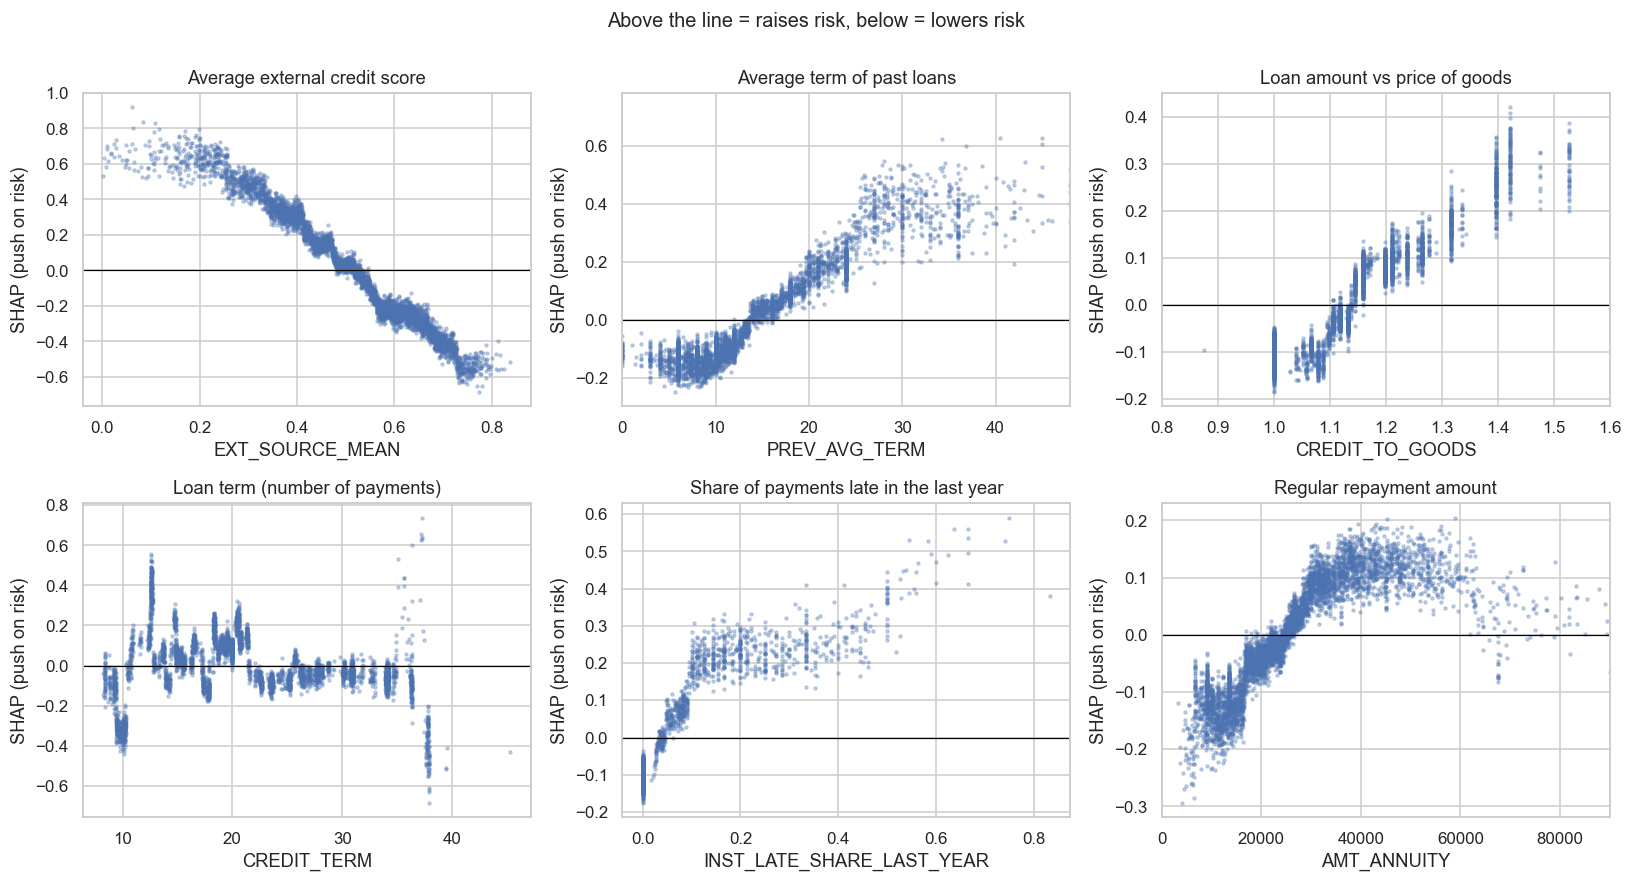

,Q1 (lowest),Q2,Q3,Q4,Q5 (highest)
Average external credit score,0.481,0.195,-0.032,-0.233,-0.395
Average term of past loans,-0.143,-0.124,-0.078,0.072,0.289
Loan amount vs price of goods,-0.103,-0.102,-0.041,0.074,0.167
Loan term (number of payments),-0.040,0.063,0.114,-0.051,-0.081
Regular repayment amount,-0.131,-0.064,0.001,0.087,0.109


In [6]:
sv = pd.DataFrame(shap_values, columns=sample.columns, index=sample.index)
panels = ["EXT_SOURCE_MEAN", "PREV_AVG_TERM", "CREDIT_TO_GOODS", "CREDIT_TERM", "INST_LATE_SHARE_LAST_YEAR", "AMT_ANNUITY"]
clip = {"CREDIT_TO_GOODS": (0.8, 1.6), "PREV_AVG_TERM": (0, 48), "AMT_ANNUITY": (0, 90000)}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flat, panels):
    x = sample[f]
    ax.scatter(x, sv[f], s=4, alpha=0.3, color="#4C72B0")
    ax.axhline(0, color="black", lw=0.8)
    if f in clip: ax.set_xlim(*clip[f])
    ax.set_title(label_of(f)); ax.set_xlabel(f); ax.set_ylabel("SHAP (push on risk)")
fig.suptitle("Above the line = raises risk, below = lowers risk", y=1.0, fontsize=13)
fig.tight_layout()
save(fig, "21_shap_dependence")
plt.show()

# Average push by value range, to read the shapes precisely
summary = {}
for f in ["EXT_SOURCE_MEAN", "PREV_AVG_TERM", "CREDIT_TO_GOODS", "CREDIT_TERM", "AMT_ANNUITY"]:
    q = pd.qcut(sample[f], 5, duplicates="drop")
    summary[label_of(f)] = sv[f].groupby(q, observed=True).mean().round(3).values
pd.DataFrame(summary, index=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]).T

**Interpretation:**
- **Average external score:** a smooth, steep **downward** line. Low scores add a lot of risk and high scores remove a lot. The strongest and simplest relationship.
- **Average term of past loans:** applicants whose previous loans were long (more than about 18 payments) get a clear risk **increase**, while short past loans lower risk.
- **Loan amount vs price of goods:** up to about 1.1 (borrowing close to the item's price) **lowers** risk, and above about 1.15 **raises** it, increasingly so. This confirms the EDA finding and makes it an obvious lever: borrowing closer to the item's price lowers predicted risk.
- **Loan term:** **not a straight line.** Short loans (about 12 payments or fewer) and long loans (more than about 23 payments) lower risk, while medium-length loans (about 13–22 payments) raise it. Different loan products attract different customers, and the model has learned this non-linear pattern by itself (logistic regression would force a straight line). For the path to approval, it means the right change in term depends on the applicant; *"just lengthen the term"* isn't always right.
- **Regular repayment amount:** larger repayments steadily raise risk, the repayment-burden effect from EDA.
- **Late payments in the last year:** any recent lateness pushes risk up, and more lateness pushes it further.

## 6. Local view: explaining individual applicants

This is what SecondLook shows a loan officer. We pick three real test applicants:
1. a **clear approval** (PD around 2%),
2. a **borderline decline** (PD just above the 0.17 cutoff), the kind of applicant SecondLook is built for, and
3. a **clear decline** (PD above 45%).

For each one, the chart shows the 10 features that pushed the score most. **Red bars push risk up, blue bars push it down**, and each label shows the applicant's actual value.

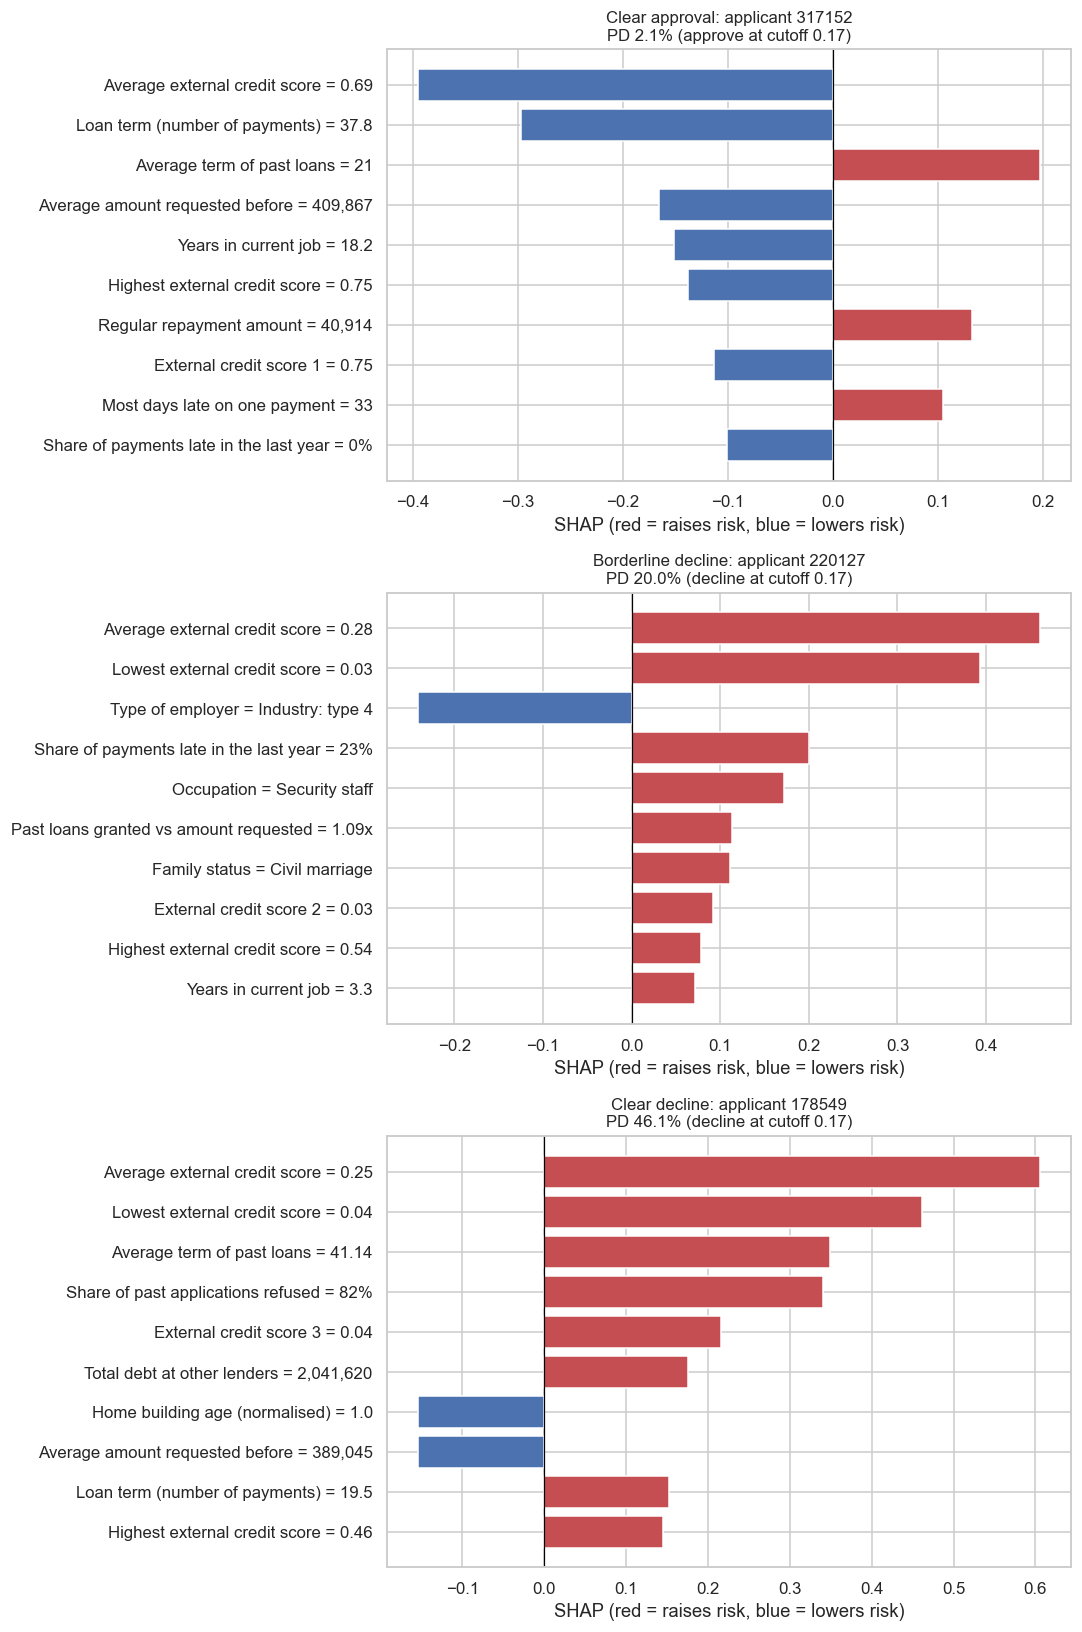

In [7]:
def pick(condition):
    return pd_test[condition].index[0]          # first test applicant meeting the condition (reproducible)

examples = {
    "Clear approval": pick((pd_test > 0.02) & (pd_test < 0.03)),
    "Borderline decline": pick((pd_test > cutoff + 0.01) & (pd_test < cutoff + 0.03)),
    "Clear decline": pick(pd_test > 0.45),
}

def plot_explanation(result, title, ax, n=10):
    t = result["all"].head(n).iloc[::-1]
    colors = np.where(t["shap"] > 0, "#C44E52", "#4C72B0")
    ax.barh([f"{l} = {v}" for l, v in zip(t["label"], t["value"])], t["shap"], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{title}\nPD {result['pd']:.1%} ({'approve' if result['pd'] < cutoff else 'decline'} at cutoff {cutoff})", fontsize=11)
    ax.set_xlabel("SHAP (red = raises risk, blue = lowers risk)")

results = {}
fig, axes = plt.subplots(3, 1, figsize=(10, 15))
for ax, (name, idx) in zip(axes, examples.items()):
    results[name] = explainer.explain(X_test.loc[[idx]])
    plot_explanation(results[name], f"{name}: applicant {test.loc[idx, ID_COL]}", ax)
fig.tight_layout()
save(fig, "22_shap_individual")
plt.show()

Below are the same explanations as tables, the format the decision letter will use: the **top 5 reasons risk went up** and the **top 5 reasons it went down**.

In [8]:
for name, idx in examples.items():
    r = results[name]
    print(f"\n{'=' * 90}\n{name.upper()}: applicant {test.loc[idx, ID_COL]}   PD = {r['pd']:.1%}   "
          f"actual outcome: {'defaulted' if test.loc[idx, TARGET_COL] == 1 else 'repaid'}")
    print("\nRaised risk:")
    print(r["raises"][["label", "value", "category", "shap"]].to_string(index=False))
    print("\nLowered risk:")
    print(r["lowers"][["label", "value", "category", "shap"]].to_string(index=False))


CLEAR APPROVAL: applicant 317152   PD = 2.1%   actual outcome: repaid

Raised risk:
                            label    value       category  shap
       Average term of past loans       21 credit history 0.198
         Regular repayment amount   40,914     actionable 0.133
    Most days late on one payment       33 credit history 0.105
Population density of home region     0.03        profile 0.096
                       Occupation Laborers        profile 0.085

Lowered risk:
                          label   value       category   shap
  Average external credit score    0.69 external score -0.395
 Loan term (number of payments)    37.8     actionable -0.297
Average amount requested before 409,867 credit history -0.166
           Years in current job    18.2        profile -0.151
  Highest external credit score    0.75 external score -0.138

BORDERLINE DECLINE: applicant 220127   PD = 20.0%   actual outcome: repaid

Raised risk:
                                  label          value

**Interpretation:**

**1. Clear approval (PD ≈ 2.1%).** The biggest factor is a **high average external score (0.69)**, which pulls risk well down. A **long loan term (about 38 payments)**, a history of larger previous loans and **18 years in the same job** help too. A few factors raise risk slightly (e.g. a long average term on past loans, a fairly high repayment amount, one payment 33 days late in the past), but they are outweighed. Even a clear approval has risk factors; the model weighs them against strengths.

**2. Borderline decline (PD ≈ 20%, just above the 17% cutoff).** This applicant **actually repaid**. The risk comes mainly from **low external scores** (average 0.28, lowest 0.03) and **late payments on 23% of installments in the last year**. Their **employer type** lowers risk, and they have no debt at other lenders and no past refusals. This is a typical SecondLook case: declined by a small margin, with a mix of real warning signs and real strengths. A loan officer seeing this breakdown can judge whether, for example, the late payments were a one-off. Note that **family status** also appears in the chart (7th, a small push). It's a sensitive characteristic, so the decision letter must **not** cite it as a reason and the path to approval must never suggest changing it. This is exactly why every feature is tagged with a category.

**3. Clear decline (PD ≈ 46%).** **Very low external scores** (0.25 average, 0.04 lowest) plus **82% of past applications refused** and long past loan terms. Even here, about **54%** of applicants with similar scores would repay, but the risk is high enough that a decline is reasonable without changes to the application.

In every case the model's reasons are **specific and checkable**. That is exactly what the letter generator needs.

## 7. Borderline applicants: what pushes them over the cutoff?

For SecondLook's target group (the ~2,600 test applicants with PD between 0.17 and 0.22), we find each applicant's **single biggest risk-raising factor** and their **top three**, then ask two questions:

1. **Can the applicant change it?** We label each feature as **actionable** (loan terms that can be restructured), **external score**, **credit history** (can improve over time, but not today), **profile** or **sensitive**.
2. **Do sensitive characteristics drive decisions?** Age, family status and number of children must never be suggested as something to change, and shouldn't be what pushes someone into a decline.

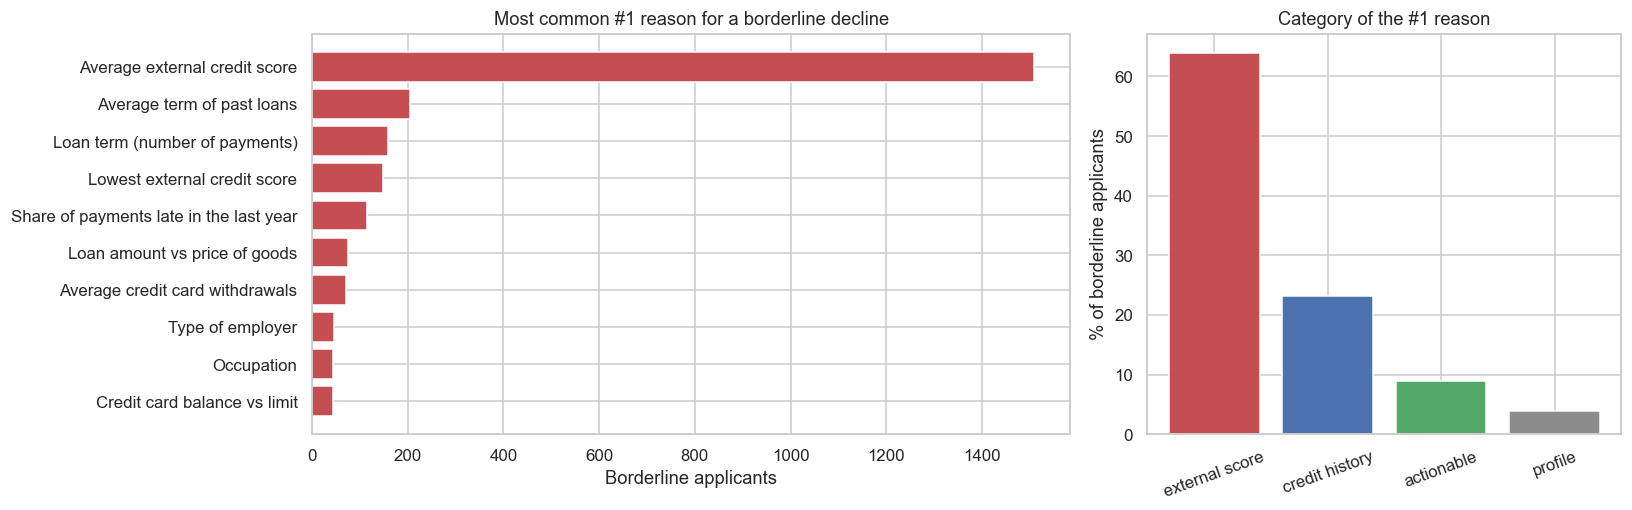

Borderline applicants: 2,611
Share with an ACTIONABLE loan term among their top 3 risk reasons: 32.3%
Share with a SENSITIVE feature among their top 3 risk reasons:      0.4%


In [9]:
band = saved["BORDERLINE"].values
X_band = X_test[band]
sv_band = explainer.shap_values(X_band)
cols = X_band.columns

top1 = pd.Series(cols[sv_band.argmax(axis=1)])
top3_idx = np.argsort(-sv_band, axis=1)[:, :3]
top3_cats = [[category_of(cols[j]) for j in row] for row in top3_idx]

reason_counts = top1.map(label_of).value_counts().head(10)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].barh(reason_counts.index[::-1], reason_counts.values[::-1], color="#C44E52")
axes[0].set(xlabel="Borderline applicants", title="Most common #1 reason for a borderline decline")
cat_share = top1.map(category_of).value_counts(normalize=True) * 100
axes[1].bar(cat_share.index, cat_share.values, color=[palette[c] for c in cat_share.index])
axes[1].set(ylabel="% of borderline applicants", title="Category of the #1 reason")
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
save(fig, "23_borderline_reasons")
plt.show()

print(f"Borderline applicants: {len(X_band):,}")
print(f"Share with an ACTIONABLE loan term among their top 3 risk reasons: {np.mean([('actionable' in c) for c in top3_cats]):.1%}")
print(f"Share with a SENSITIVE feature among their top 3 risk reasons:      {np.mean([('sensitive' in c) for c in top3_cats]):.1%}")

**Interpretation:**
- **Low external scores are the #1 reason for most borderline declines** (more than half name the average external score as their single biggest factor). These scores summarise credit behaviour elsewhere, and an applicant can't change them today.
- The next most common #1 reasons are **past loan terms**, **the current loan's term**, **recent late payments** and **loan amount vs price of goods**.
- For **about one in three borderline applicants, an actionable loan term is among their top three risk reasons.** For them, restructuring the loan (a different term, or borrowing closer to the item price) could plausibly bring PD under the cutoff. For the rest, the honest message is about what would help *over time* (e.g. a record of on-time payments), plus the strengths an officer can weigh in a manual review.
- **Sensitive characteristics almost never drive borderline declines:** they appear among the top three reasons for **under 1%** of these applicants. The model's decisions near the cutoff are driven by credit behaviour and loan structure, not by who the applicant is.

**Rules this sets for the next steps:**
1. **Decision letters** cite only the top non-sensitive reasons, in plain language, always alongside the strengths.
2. The **path to approval** only changes **actionable** features (loan amount, term, amount vs goods price) and re-scores with the real model. It never suggests changing age, family or other personal characteristics.
3. The **faithfulness check** compares every reason in a letter against this SHAP table.

## 8. Summary

| Question | Answer |
|---|---|
| Can we trust the explanations? | Yes: SHAP values add up to the model's output exactly (error ≈ 10⁻¹⁴) |
| What drives risk overall? | External scores first; then past behaviour (past loan terms, recent late payments, granted vs requested); then loan structure (term, amount vs goods price, repayment amount) |
| Does the model learn non-linear patterns? | Yes: e.g. medium loan terms are riskiest, while short and long terms are safer |
| Can every score be explained individually? | Yes: top reasons up and down, with the applicant's actual values, in plain language |
| What pushes borderline applicants over? | Mostly low external scores; about 1 in 3 have an actionable loan term among their top 3 reasons |
| Do sensitive characteristics drive decisions? | Almost never: under 1% of borderline applicants have one among their top 3 reasons |

**Reusable code:** `src/secondlook/explain.py` provides `Explainer.explain(applicant)`, which returns the PD and the top reasons in both directions with plain-English labels. The Streamlit app and the Claude letter generator will call this directly.

**Next: Step 6, Claude decision letters**, written from these SHAP reasons and checked against them.